# Parte 1: Modelo preditivo de pico de risco cardíaco

**FIAP · Graduação em Inteligência Artificial · Fase 6**
**Sistema Preditivo Multiagente para Eventos Cardíacos**

Este notebook cobre a Parte 1 da atividade:

1. Geração da base sintética fornecida no enunciado.
2. Análise exploratória rápida.
3. Separação entre treino e teste.
4. Comparação de classificadores supervisionados com validação cruzada.
5. Avaliação do modelo escolhido: acurácia, precisão, recall, F1, ROC AUC e matriz de confusão.
6. Salvamento do modelo para a integração com o sistema multiagente (Parte 2).
7. Simulação de previsão para um novo paciente.

> Os dados são **sintéticos**. Nenhum dado real de paciente foi usado.

## 0. Bibliotecas

In [1]:
# No Google Colab todas as bibliotecas abaixo já vêm instaladas.
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Geração da base sintética

Código fornecido no enunciado, sem alterações. A variável alvo `pico_risco` vale 1 quando
pelo menos **dois** dos seis critérios abaixo estão presentes:

| Critério | Limite |
|---|---|
| Carga do sistema | > 80% |
| Tempo de espera | > 60 min |
| SpO2 média | < 92% |
| Frequência cardíaca média | > 110 bpm |
| Eventos nas últimas 24 h | > 4 |
| Disponibilidade de recursos | < 40% |

In [2]:
np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

df["pico_risco"] = (risk_score >= 2).astype(int)

FEATURES = [c for c in df.columns if c != "pico_risco"]
TARGET = "pico_risco"
df.head()

,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


## 2. Análise exploratória

In [3]:
print("Formato:", df.shape)
print("Valores ausentes:", int(df.isna().sum().sum()))
print("\nDistribuição da variável alvo:")
print(df[TARGET].value_counts().rename({0: "sem pico (0)", 1: "pico de risco (1)"}))
print(f"\nProporção de picos: {df[TARGET].mean():.1%}")
df.describe().T.round(2)

Formato: (5000, 11)
Valores ausentes: 0

Distribuição da variável alvo:
pico_risco
sem pico (0)         3671
pico de risco (1)    1329
Name: count, dtype: int64

Proporção de picos: 26.6%


,count,mean,std,min,25%,50%,75%,max
idade_media,5000.0,55.06,11.93,18.00,47.11,55.16,62.99,90.00
carga_sistema,5000.0,64.64,19.99,30.00,47.60,64.43,81.68,99.98
tempo_espera,5000.0,45.24,19.38,5.00,31.84,45.14,58.28,113.58
fc_media,5000.0,85.31,14.90,50.00,75.00,85.22,95.60,150.00
spo2_media,5000.0,94.92,2.87,83.43,92.90,94.98,97.01,100.00
pa_sistolica,5000.0,124.89,19.53,80.00,111.20,125.06,138.05,198.83
temperatura,5000.0,24.00,5.08,10.00,20.51,23.97,27.51,40.00
densidade_eventos,5000.0,3.00,1.73,0.00,2.00,3.00,4.00,13.00
eventos_24h,5000.0,1.99,1.42,0.00,1.00,2.00,3.00,9.00
disponibilidade_recursos,5000.0,60.27,23.03,20.04,40.19,60.87,80.39,99.99


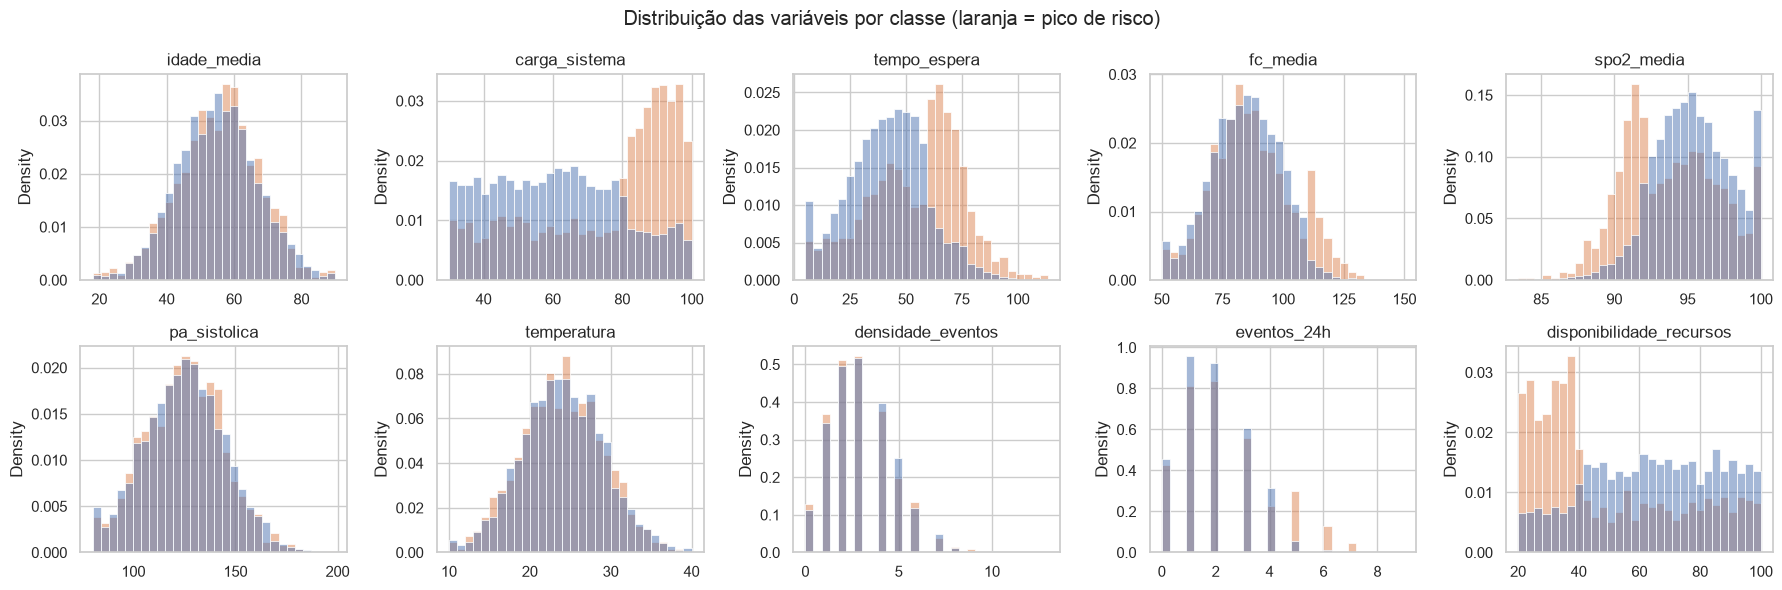

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat="density", common_norm=False, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distribuição das variáveis por classe (laranja = pico de risco)")
plt.tight_layout()
plt.show()

**Leitura:** a base é desbalanceada, com cerca de 27% de picos. Por isso a separação treino/teste
é **estratificada** e avaliamos também precisão, recall e F1, e não apenas a acurácia.
As variáveis que entram na regra do alvo (carga, espera, SpO2, FC, eventos 24 h e recursos)
mostram distribuições diferentes entre as classes. Idade, PA, temperatura e densidade de eventos
não participam da regra e têm distribuições praticamente iguais.

## 3. Separação entre treino e teste (80/20, estratificada)

In [4]:
X = df[FEATURES]
y = df[TARGET]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Treino:", X_treino.shape, f"| picos: {y_treino.mean():.1%}")
print("Teste: ", X_teste.shape, f"| picos: {y_teste.mean():.1%}")

Treino: (4000, 10) | picos: 26.6%
Teste:  (1000, 10) | picos: 26.6%


## 4. Comparação de classificadores

Comparamos três classificadores supervisionados vistos nas disciplinas, usando
**validação cruzada estratificada com 5 folds** apenas no conjunto de treino.
A métrica de comparação é o F1, que equilibra precisão e recall na classe minoritária.

In [5]:
candidatos = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
linhas = []
for nome, modelo in candidatos.items():
    f1_cv = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="f1")
    acc_cv = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="accuracy")
    linhas.append({"modelo": nome, "acurácia CV": acc_cv.mean(), "F1 CV": f1_cv.mean(), "F1 desvio": f1_cv.std()})

comparacao = pd.DataFrame(linhas).set_index("modelo").round(4)
comparacao

,acurácia CV,F1 CV,F1 desvio
modelo,,,
Regressão Logística,0.8298,0.6427,0.0313
Árvore de Decisão,0.9962,0.9930,0.0033
Random Forest,0.9975,0.9953,0.0021


**Escolha: Random Forest.** O alvo é definido por limites (por exemplo, `fc_media > 110`) e pela
contagem de critérios. Árvores capturam esse tipo de corte de forma natural, e o ensemble de
300 árvores reduz a variância de uma árvore isolada. A Regressão Logística tem desempenho bem
menor porque a fronteira "pelo menos 2 de 6 critérios" não é linear nas variáveis originais.

## 5. Treinamento e avaliação do modelo escolhido

In [6]:
modelo = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
modelo.fit(X_treino, y_treino)

y_pred = modelo.predict(X_teste)
y_prob = modelo.predict_proba(X_teste)[:, 1]

metricas = {
    "acuracia": accuracy_score(y_teste, y_pred),
    "precisao": precision_score(y_teste, y_pred),
    "recall": recall_score(y_teste, y_pred),
    "f1": f1_score(y_teste, y_pred),
    "roc_auc": roc_auc_score(y_teste, y_prob),
}
metricas = {k: round(float(v), 4) for k, v in metricas.items()}
vn, fp, fn, vp = confusion_matrix(y_teste, y_pred).ravel()
metricas["matriz_confusao"] = {"VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp)}

print(json.dumps(metricas, indent=2, ensure_ascii=False))
print()
print(classification_report(y_teste, y_pred, target_names=["sem pico", "pico"], digits=4))

{
  "acuracia": 0.999,
  "precisao": 1.0,
  "recall": 0.9962,
  "f1": 0.9981,
  "roc_auc": 1.0,
  "matriz_confusao": {
    "VN": 734,
    "FP": 0,
    "FN": 1,
    "VP": 265
  }
}

              precision    recall  f1-score   support

    sem pico     0.9986    1.0000    0.9993       734
        pico     1.0000    0.9962    0.9981       266

    accuracy                         0.9990      1000
   macro avg     0.9993    0.9981    0.9987      1000
weighted avg     0.9990    0.9990    0.9990      1000



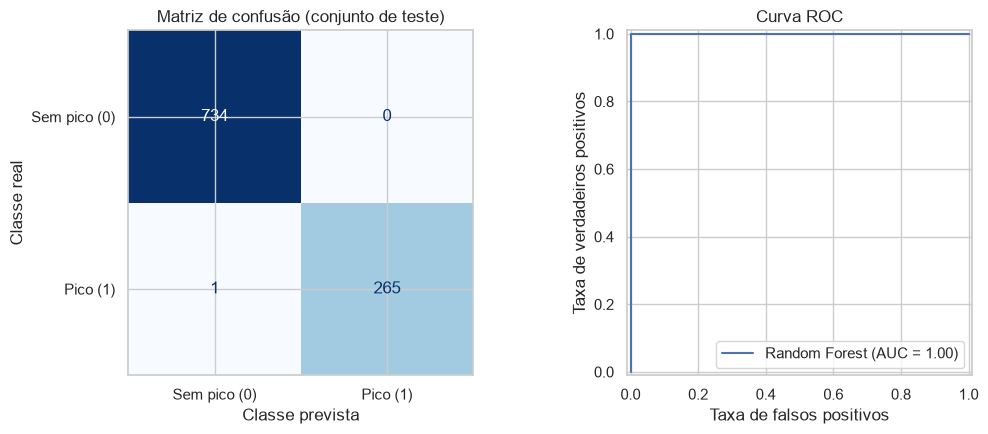

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_pred, display_labels=["Sem pico (0)", "Pico (1)"], cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Matriz de confusão (conjunto de teste)")
axes[0].set_xlabel("Classe prevista")
axes[0].set_ylabel("Classe real")
RocCurveDisplay.from_predictions(y_teste, y_prob, name="Random Forest", ax=axes[1])
axes[1].set_xlabel("Taxa de falsos positivos")
axes[1].set_ylabel("Taxa de verdadeiros positivos")
axes[1].set_title("Curva ROC")
plt.tight_layout()
plt.show()

**Análise da matriz de confusão:**

- **Verdadeiros negativos e verdadeiros positivos** concentram praticamente todo o conjunto de teste.
- **Falsos negativos** são o erro mais grave neste contexto, pois um pico real não seria sinalizado.
  O modelo comete apenas 1 erro desse tipo em 266 picos, ou seja, recall acima de 99%.
- **Falsos positivos** geram alarmes desnecessários e custo operacional. Não houve nenhum no teste.

O desempenho quase perfeito é esperado: o alvo é uma função **determinística** das próprias
variáveis de entrada, sem ruído. Em dados reais, que têm ruído de medição e fatores não
observados, o desempenho seria menor. Essa limitação é discutida no relatório técnico.

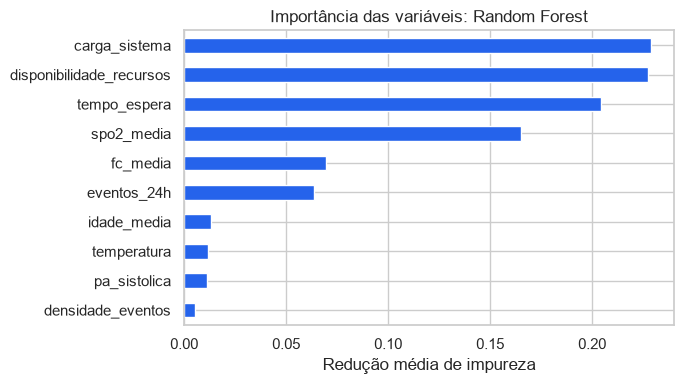

In [8]:
importancias = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
importancias.plot.barh(figsize=(7, 4), color="#2563eb", title="Importância das variáveis: Random Forest")
plt.xlabel("Redução média de impureza")
plt.tight_layout()
plt.show()

As seis variáveis da regra do alvo dominam a importância. Idade, PA sistólica, temperatura
e densidade de eventos têm importância próxima de zero, o que confirma que o modelo aprendeu
a estrutura real da base e não ruído.

## 6. Salvamento do modelo

O modelo é salvo com `joblib` junto com a lista de variáveis, as métricas e a versão do
scikit-learn. O sistema multiagente da Parte 2 carrega exatamente este pacote.

- **No Colab**, o arquivo é salvo na pasta atual e baixado automaticamente.
- **No repositório**, ele é salvo em `src/models/modelo_pico_risco.joblib`.

In [9]:
pacote = {
    "modelo": modelo,
    "algoritmo": "Random Forest",
    "features": FEATURES,
    "target": TARGET,
    "metricas_teste": metricas,
    "versao_sklearn": sklearn.__version__,
}

pasta_repo = Path("../models")
destino = (pasta_repo if pasta_repo.exists() else Path(".")) / "modelo_pico_risco.joblib"
joblib.dump(pacote, destino)
print("Modelo salvo em:", destino.resolve())

try:
    from google.colab import files  # disponível apenas no Colab
    files.download(str(destino))
except ImportError:
    pass

Modelo salvo em: /Users/seberino/dev/fiap_ano2_fase6_trabaho/src/models/modelo_pico_risco.joblib


## 7. Simulação de previsão para um novo paciente

Usamos o caso do enunciado. Ele traz a chave `"disponibilidade recursos"` com espaço,
então normalizamos os nomes das colunas antes de consultar o modelo.

In [11]:
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade recursos": 25
}])
novo_caso.columns = novo_caso.columns.str.strip().str.replace(" ", "_")

modelo_carregado = joblib.load(destino)
prob = modelo_carregado["modelo"].predict_proba(novo_caso[modelo_carregado["features"]])[0, 1]
classe = "ALTO" if prob >= 0.70 else "MODERADO" if prob >= 0.30 else "BAIXO"
print(f"RISCO PREVISTO: {prob:.2f}")
print(f"CLASSIFICAÇÃO: {classe}")

RISCO PREVISTO: 0.99
CLASSIFICAÇÃO: ALTO


### Prévia do cruzamento com a base de protocolos

Na Parte 2, esse cruzamento é feito pelo **Agente Especialista em Protocolos**. Aqui fazemos
uma versão simples só para mostrar o resultado esperado.

In [12]:
protocolos = [
    ("spo2_media", "<", 88, "Se SPO2 < 88% → iniciar suporte respiratório imediato"),
    ("carga_sistema", ">", 85, "Se carga do sistema > 85% → abrir unidades temporárias"),
    ("fc_media", ">", 120, "Se FC > 120 → iniciar monitoramento intensivo"),
    ("eventos_24h", ">", 5, "Se eventos_24h > 5 → ativar equipe de resposta rápida"),
    ("disponibilidade_recursos", "<", 30, "Se disponibilidade_recursos < 30% → redistribuir insumos"),
    ("tempo_espera", ">", 90, "Se tempo_espera > 90 min → priorizar triagem emergencial"),
    ("temperatura", ">", 38, "Se temperatura > 38°C média → iniciar protocolo infeccioso"),
    ("densidade_eventos", ">", 6, "Se densidade_eventos > 6 → ativar plano de contingência"),
    ("pa_sistolica", "<", 90, "Se PA sistólica < 90 → iniciar protocolo de choque"),
]
paciente = novo_caso.iloc[0]
sugeridos = [txt for campo, op, lim, txt in protocolos
             if (op == ">" and paciente[campo] > lim) or (op == "<" and paciente[campo] < lim)]
if classe == "ALTO":
    sugeridos.insert(0, "Se risco sistêmico alto → ativar estado de emergência")

print(f"RISCO PREVISTO: {prob:.2f}\n")
print("PROTOCOLOS SUGERIDOS:")
for p in sugeridos:
    print("-", p)

RISCO PREVISTO: 0.99

PROTOCOLOS SUGERIDOS:
- Se risco sistêmico alto → ativar estado de emergência
- Se carga do sistema > 85% → abrir unidades temporárias
- Se disponibilidade_recursos < 30% → redistribuir insumos
- Se densidade_eventos > 6 → ativar plano de contingência


**Observação:** o exemplo de saída do enunciado lista o protocolo de SpO2, mas o paciente tem
SpO2 de 89%, acima do limite de 88%. Seguimos a regra da base de protocolos à risca. No sistema
multiagente, valores próximos do limite, como esse, aparecem como **parâmetros em zona de atenção**.

## Conclusão

O Random Forest atingiu acurácia de 99,9% e recall de 99,6% no teste. O modelo salvo é
consumido pelo **Agente Analista de Risco** do sistema multiagente (Parte 2, pasta `src/multiagente`).